# NB2 — Task 2a: Architectural Variations
____________________________________________________________________________________________________

In NB1 the baseline CNN reached **~90% test accuracy** but clearly **overfitted**: the training accuracy went to 100% while the validation loss started to increase after ~6 epochs.

In this notebook we study how the **architecture** changes the results. We change **one factor at a time** with respect to the baseline, and keep everything else fixed (same data, same optimizer SGD lr=0.01 momentum=0.9, same number of epochs, same seed):

| Experiment | What we change | Values |
|---|---|---|
| A. Depth (conv) | number of convolutional blocks | 2, **3**, 4, 5 |
| B. Depth (fc) | number of fully connected layers | 1, **2**, 3 |
| C. Kernel size | size of the convolution kernels | **3x3**, 5x5, 7x7 |
| D. Padding | "same" padding vs no padding ("valid") | **same**, valid |
| E. Downsampling | MaxPool vs strided convolution | **MaxPool**, stride 2 |
| F. Batch Normalization | BN after each convolution | **no**, yes |
| G. Combination | best choice of each experiment together | |

(**bold** = baseline value)

For each configuration we record: number of parameters, inference latency, peak validation accuracy, generalization gap and theoretical receptive field.

## 0. Setup

Same setup as NB1 (device, seed, paths, data).

In [1]:
import os
import json
import time
import random

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

ON_KAGGLE = os.path.exists("/kaggle/input")

def find_path(name, search_roots):
    # walk the search folders and return the first file / folder called `name`
    for search_root in search_roots:
        for root, dirs, files in os.walk(search_root):
            if name in dirs or name in files:
                return os.path.join(root, name)
    return None

SEARCH_ROOTS = ["/kaggle/input"] if ON_KAGGLE else ["..", "../.."]
DATA_ROOT = find_path("EuroSAT_RGB", SEARCH_ROOTS)
SPLITS_FILE = find_path("splits.json", SEARCH_ROOTS)

OUT_DIR = "/kaggle/working" if ON_KAGGLE else "."
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")
RES_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

NUM_WORKERS = 4 if ON_KAGGLE else 0

print("DATA_ROOT  :", DATA_ROOT)
print("SPLITS_FILE:", SPLITS_FILE)

Using device: cuda:0
DATA_ROOT  : /kaggle/input/datasets/waseemalastal/eurosat-rgb-dataset/EuroSAT_RGB
SPLITS_FILE: /kaggle/input/notebooks/emilioyared/aide500-nb0-setup-data-run-1010-1100/splits.json


In [2]:
with open(SPLITS_FILE) as f:
    splits = json.load(f)

classes = splits["classes"]
num_classes = len(classes)
MEAN, STD = splits["mean"], splits["std"]

# no data augmentation in this notebook (studied in NB4)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])

dataset = torchvision.datasets.ImageFolder(root=DATA_ROOT, transform=transform)
trainset = Subset(dataset, splits["train"])
valset = Subset(dataset, splits["val"])
testset = Subset(dataset, splits["test"])
print("train: %d | val: %d | test: %d" % (len(trainset), len(valset), len(testset)))

BATCH_SIZE = 64
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
valloader = DataLoader(valset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
testloader = DataLoader(testset, batch_size=256, shuffle=False, num_workers=NUM_WORKERS)

train: 18900 | val: 4050 | test: 4050


## a. A configurable CNN

To compare many architectures without writing a new class each time, we write **one** class `ConfigNet` whose structure depends on its arguments:

- `n_blocks`: number of convolutional blocks. Each block is `Conv → (BatchNorm) → ReLU → (MaxPool)`. The number of feature maps doubles at each block: 32, 64, 128, 256, 256 (capped at 256).
- `kernel_size`: 3, 5 or 7.
- `padding`: `"same"` → $p = \lfloor k/2 \rfloor$, so the convolution keeps the size; `"valid"` → $p = 0$, so each convolution removes $k-1$ pixels.
- `downsample`: `"pool"` → MaxPool 2x2 after the convolution; `"stride"` → the convolution itself has stride 2 (no pooling layer).
- `use_bn`: add a Batch Normalization layer after each convolution.
- `n_fc`: number of fully connected layers (1, 2 or 3).

The layers of each block are put together with ``nn.Sequential`` (as for the classification head in the transfer learning script): the input goes through the layers one after the other, in the order given.

**Recap:** output size of a Conv2d / MaxPool2d layer:

$$h_{out} = \left\lfloor \frac{h_{in} + 2p - k}{s} \right\rfloor + 1$$

We use this formula in the constructor to compute the size of the last feature maps, i.e. the number of inputs of the first fully connected layer (the value we wrote by hand, `128 * 8 * 8`, in NB1).

In [3]:
class ConfigNet(nn.Module):
    def __init__(self, n_blocks=3, kernel_size=3, padding="same", downsample="pool", use_bn=False, n_fc=2, num_classes=10):
        super(ConfigNet, self).__init__()
        channels = [3] + [min(32 * 2 ** i, 256) for i in range(n_blocks)]  # e.g. n_blocks=3 -> [3, 32, 64, 128]
        p = kernel_size // 2 if padding == "same" else 0
        s = 2 if downsample == "stride" else 1

        blocks = []
        h = 64  # input images are 64x64
        for i in range(n_blocks):
            layers = []
            # with BatchNorm, the conv bias is useless (BN subtracts the mean and adds its own bias beta)
            layers.append(nn.Conv2d(channels[i], channels[i + 1], kernel_size, stride=s, padding=p, bias=not use_bn))
            h = (h + 2 * p - kernel_size) // s + 1           # size after the convolution
            if use_bn:
                layers.append(nn.BatchNorm2d(channels[i + 1]))
            layers.append(nn.ReLU())
            if downsample == "pool":
                layers.append(nn.MaxPool2d(2, 2))
                h = (h - 2) // 2 + 1                         # size after the pooling
            blocks.append(nn.Sequential(*layers))
        self.features = nn.Sequential(*blocks)

        assert h >= 1, "the feature maps disappear (size %d): too many blocks for this padding / kernel" % h
        self.flat_features = channels[-1] * h * h            # number of inputs of the first fc layer
        self.out_size = h

        # fully connected layers: 1 -> [flat, 10] | 2 -> [flat, 256, 10] | 3 -> [flat, 256, 128, 10]
        fc_sizes = [self.flat_features] + [256, 128][:n_fc - 1] + [num_classes]
        fc_layers = []
        for i in range(n_fc):
            fc_layers.append(nn.Linear(fc_sizes[i], fc_sizes[i + 1]))
            if i < n_fc - 1:                                 # no ReLU after the last layer (we want raw scores)
                fc_layers.append(nn.ReLU())
        self.classifier = nn.Sequential(*fc_layers)

    def forward(self, x):
        x = self.features(x)                     # [B, C, h, h]
        x = x.view(-1, self.flat_features)       # [B, C*h*h] flatten
        x = self.classifier(x)                   # [B, 10]
        return x


# check: the default configuration is exactly the baseline of NB1
net = ConfigNet()
print(net)
print("last feature maps: %dx%d | flat features: %d" % (net.out_size, net.out_size, net.flat_features))
print("parameters:", sum(p.numel() for p in net.parameters()))

ConfigNet(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Linear(in_features=8192, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=10, bias=True)
  )
)
last feature maps: 8x8 | flat features: 8192
parameters: 2193226


**Theoretical receptive field**

The **receptive field** of a neuron is the region of the input image that can influence its value. A neuron of the first 3x3 convolution "sees" 3x3 pixels; after a pooling and another 3x3 convolution it sees a bigger region, and so on.

For a stack of layers with kernels $k_l$ and strides $s_l$, the receptive field $r$ of the last layer is computed recursively:

$$r_l = r_{l-1} + (k_l - 1) \cdot j_{l-1}, \qquad j_l = j_{l-1} \cdot s_l, \qquad r_0 = 1,\ j_0 = 1$$

where $j$ (the "jump") is the distance, in input pixels, between two neighbouring neurons of the layer.

A larger receptive field allows the last convolution to "see" larger structures (a whole field, a river bend). Bigger kernels and more layers both increase it.

In [4]:
def receptive_field(net):
    r, j = 1, 1
    for m in net.features.modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d)):
            k = m.kernel_size if isinstance(m.kernel_size, int) else m.kernel_size[0]
            s = m.stride if isinstance(m.stride, int) else m.stride[0]
            r = r + (k - 1) * j
            j = j * s
    return r

print("receptive field of the baseline: %dx%d pixels (the input is 64x64)" % (receptive_field(net), receptive_field(net)))

receptive field of the baseline: 22x22 pixels (the input is 64x64)


## b. Training and evaluation helpers

Same `train_one_epoch` and `evaluate` functions as in NB1, plus:

- `measure_latency`: average time to classify **one** image (batch of 1).
- `run_experiment`: builds a `ConfigNet` from a configuration, trains it for `n_epochs` epochs, saves the best checkpoint (best validation accuracy) and the history, and returns a summary.

Before each experiment we call `set_seed(SEED)`: every network starts from the same random state, so the differences come from the architecture and not from luck.

In [5]:
def train_one_epoch(net, loader, criterion, optimizer):
    net.train()
    running_loss, correct, total = 0.0, 0, 0
    for i, data in enumerate(loader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100.0 * correct / total


def evaluate(net, loader, criterion):
    net.eval()
    running_loss, total = 0.0, 0
    all_preds, all_labels = [], []
    with torch.no_grad():
        for data in loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = net(images)
            running_loss += criterion(outputs, labels).item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            all_preds.append(predicted.cpu())
            all_labels.append(labels.cpu())
            total += labels.size(0)
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    acc = 100.0 * (all_preds == all_labels).mean()
    per_class_acc = [100.0 * (all_preds[all_labels == c] == c).mean() for c in range(num_classes)]
    return running_loss / total, acc, per_class_acc, all_preds, all_labels


def measure_latency(net, n_runs=100):
    net.eval()
    x = torch.randn(1, 3, 64, 64).to(device)
    with torch.no_grad():
        for _ in range(10):  # warm-up
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()  # wait for the GPU to finish before reading the time
        start = time.time()
        for _ in range(n_runs):
            net(x)
        if device.type == "cuda": torch.cuda.synchronize()
    return (time.time() - start) / n_runs * 1000  # milliseconds per image

In [6]:
n_epochs = 30
LR = 0.01
criterion = nn.CrossEntropyLoss()

all_histories = {}   # name -> history
all_summaries = {}   # name -> summary
all_configs = {}     # name -> config


def run_experiment(name, config):
    set_seed(SEED)
    net = ConfigNet(**config).to(device)
    optimizer = optim.SGD(net.parameters(), lr=LR, momentum=0.9)
    n_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
    ckpt_path = os.path.join(CKPT_DIR, "NB2_%s.pth" % name)
    print('===== %s | %s | %d parameters | last feature maps %dx%d =====' % (name, config, n_params, net.out_size, net.out_size))

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "val_per_class_acc": [], "epoch_time": []}
    best_val_acc = 0.0
    for epoch in range(n_epochs):
        start = time.time()
        train_loss, train_acc = train_one_epoch(net, trainloader, criterion, optimizer)
        val_loss, val_acc, val_per_class_acc, _, _ = evaluate(net, valloader, criterion)
        epoch_time = time.time() - start

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_per_class_acc"].append(val_per_class_acc)
        history["epoch_time"].append(epoch_time)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(net.state_dict(), ckpt_path)

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print('[epoch %2d] train loss: %.3f | train acc: %.2f %% | val loss: %.3f | val acc: %.2f %% | %.1f s' %
                  (epoch + 1, train_loss, train_acc, val_loss, val_acc, epoch_time))

    best_epoch = int(np.argmax(history["val_acc"]))
    summary = {
        "name": name,
        "params": n_params,
        "latency_ms": measure_latency(net),
        "receptive_field": receptive_field(net),
        "best_val_acc": best_val_acc,
        "best_epoch": best_epoch + 1,
        "gen_gap": history["train_acc"][best_epoch] - history["val_acc"][best_epoch],
        "min_val_loss": min(history["val_loss"]),
        "train_time_s": sum(history["epoch_time"]),
    }
    print('-> best val acc: %.2f %% (epoch %d) | gap: %.2f | train time: %.0f s' %
          (best_val_acc, best_epoch + 1, summary["gen_gap"], summary["train_time_s"]))

    all_histories[name] = history
    all_summaries[name] = summary
    all_configs[name] = config
    with open(os.path.join(RES_DIR, "NB2_%s_history.json" % name), "w") as f:
        json.dump(history, f)
    return summary

## c. Experiments

### Baseline (reference)

We re-train the baseline of NB1 here, so that every configuration of this notebook is trained in exactly the same conditions.

In [7]:
BASELINE = dict(n_blocks=3, kernel_size=3, padding="same", downsample="pool", use_bn=False, n_fc=2)
run_experiment("baseline", BASELINE)

===== baseline | {'n_blocks': 3, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': False, 'n_fc': 2} | 2193226 parameters | last feature maps 8x8 =====
[epoch  1] train loss: 1.300 | train acc: 51.71 % | val loss: 0.908 | val acc: 66.35 % | 27.3 s
[epoch  5] train loss: 0.352 | train acc: 87.64 % | val loss: 0.442 | val acc: 84.05 % | 10.8 s
[epoch 10] train loss: 0.118 | train acc: 95.80 % | val loss: 0.478 | val acc: 86.59 % | 10.3 s
[epoch 15] train loss: 0.036 | train acc: 98.87 % | val loss: 0.707 | val acc: 84.22 % | 10.3 s
[epoch 20] train loss: 0.028 | train acc: 99.09 % | val loss: 0.490 | val acc: 90.27 % | 10.5 s
[epoch 25] train loss: 0.001 | train acc: 99.98 % | val loss: 0.530 | val acc: 91.11 % | 10.7 s
[epoch 30] train loss: 0.022 | train acc: 99.24 % | val loss: 0.571 | val acc: 88.89 % | 10.9 s
-> best val acc: 91.11 % (epoch 24) | gap: 8.87 | train time: 338 s


{'name': 'baseline',
 'params': 2193226,
 'latency_ms': 0.3803062438964844,
 'receptive_field': 22,
 'best_val_acc': np.float64(91.11111111111111),
 'best_epoch': 24,
 'gen_gap': np.float64(8.86772486772486),
 'min_val_loss': 0.38006409375755873,
 'train_time_s': 338.48922896385193}

### A. Depth: number of convolutional blocks

- **Fewer blocks** (2): fewer feature extraction steps and larger last feature maps (16x16) → the first fc layer gets a huge number of inputs → many parameters, mostly in the fc layer.
- **More blocks** (4, 5): deeper features, larger receptive field, smaller last feature maps (4x4, 2x2) → fewer fc parameters.

**Why can a deeper network be harder to train?** Each extra layer multiplies the gradients during backpropagation; without normalization, the gradients of the first layers can become very small (vanishing gradients).

In [8]:
for n_blocks in [2, 4, 5]:
    run_experiment("depth_%dblocks" % n_blocks, dict(BASELINE, n_blocks=n_blocks))

===== depth_2blocks | {'n_blocks': 2, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': False, 'n_fc': 2} | 4216522 parameters | last feature maps 16x16 =====
[epoch  1] train loss: 1.160 | train acc: 57.66 % | val loss: 0.856 | val acc: 67.78 % | 10.3 s
[epoch  5] train loss: 0.274 | train acc: 90.29 % | val loss: 0.564 | val acc: 81.85 % | 11.3 s
[epoch 10] train loss: 0.077 | train acc: 97.39 % | val loss: 0.800 | val acc: 83.19 % | 12.2 s
[epoch 15] train loss: 0.012 | train acc: 99.71 % | val loss: 0.832 | val acc: 86.22 % | 10.7 s
[epoch 20] train loss: 0.002 | train acc: 99.95 % | val loss: 0.911 | val acc: 86.74 % | 10.3 s
[epoch 25] train loss: 0.029 | train acc: 99.11 % | val loss: 1.041 | val acc: 84.69 % | 11.2 s
[epoch 30] train loss: 0.000 | train acc: 99.99 % | val loss: 0.942 | val acc: 85.75 % | 12.0 s
-> best val acc: 86.74 % (epoch 20) | gap: 13.21 | train time: 337 s
===== depth_4blocks | {'n_blocks': 4, 'kernel_size': 3, 'padding': 'same', 'downs

### B. Depth: number of fully connected layers

- 1 fc layer: the classifier is a simple **linear** function of the convolutional features.
- 3 fc layers: a deeper non-linear classifier, with more parameters (and more risk of overfitting).

In [9]:
for n_fc in [1, 3]:
    run_experiment("fc_%dlayers" % n_fc, dict(BASELINE, n_fc=n_fc))

===== fc_1layers | {'n_blocks': 3, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': False, 'n_fc': 1} | 175178 parameters | last feature maps 8x8 =====
[epoch  1] train loss: 1.137 | train acc: 58.23 % | val loss: 0.741 | val acc: 74.27 % | 11.5 s
[epoch  5] train loss: 0.329 | train acc: 88.40 % | val loss: 0.441 | val acc: 84.32 % | 11.4 s
[epoch 10] train loss: 0.100 | train acc: 96.61 % | val loss: 0.417 | val acc: 88.62 % | 11.7 s
[epoch 15] train loss: 0.054 | train acc: 98.17 % | val loss: 0.494 | val acc: 88.02 % | 12.4 s
[epoch 20] train loss: 0.010 | train acc: 99.70 % | val loss: 0.533 | val acc: 90.15 % | 12.9 s
[epoch 25] train loss: 0.037 | train acc: 98.87 % | val loss: 0.523 | val acc: 89.26 % | 12.1 s
[epoch 30] train loss: 0.001 | train acc: 99.99 % | val loss: 0.552 | val acc: 90.72 % | 11.1 s
-> best val acc: 90.74 % (epoch 28) | gap: 9.21 | train time: 358 s
===== fc_3layers | {'n_blocks': 3, 'kernel_size': 3, 'padding': 'same', 'downsample': 'p

### C. Kernel size

A bigger kernel looks at a bigger neighbourhood at once (larger receptive field) but has more weights: a conv layer has $C_{in} \times C_{out} \times k \times k$ weights, so going from 3x3 to 7x7 multiplies its parameters by $49/9 \approx 5.4$.

Note: two stacked 3x3 convolutions have the same receptive field as one 5x5 (5x5 pixels) with fewer weights ($2 \times 9 = 18$ vs $25$ per channel pair) and one more non-linearity. This is the main idea of VGG networks.

In [10]:
for k in [5, 7]:
    run_experiment("kernel_%dx%d" % (k, k), dict(BASELINE, kernel_size=k))

===== kernel_5x5 | {'n_blocks': 3, 'kernel_size': 5, 'padding': 'same', 'downsample': 'pool', 'use_bn': False, 'n_fc': 2} | 2358602 parameters | last feature maps 8x8 =====
[epoch  1] train loss: 1.521 | train acc: 41.79 % | val loss: 1.071 | val acc: 59.80 % | 11.6 s
[epoch  5] train loss: 0.416 | train acc: 85.23 % | val loss: 0.537 | val acc: 81.28 % | 10.9 s
[epoch 10] train loss: 0.127 | train acc: 95.57 % | val loss: 0.649 | val acc: 83.75 % | 11.0 s
[epoch 15] train loss: 0.068 | train acc: 97.67 % | val loss: 0.631 | val acc: 86.62 % | 10.5 s
[epoch 20] train loss: 0.027 | train acc: 99.13 % | val loss: 0.787 | val acc: 86.59 % | 11.8 s
[epoch 25] train loss: 0.036 | train acc: 98.92 % | val loss: 0.795 | val acc: 87.23 % | 10.6 s
[epoch 30] train loss: 0.002 | train acc: 99.97 % | val loss: 0.772 | val acc: 89.16 % | 11.4 s
-> best val acc: 89.16 % (epoch 30) | gap: 10.81 | train time: 324 s
===== kernel_7x7 | {'n_blocks': 3, 'kernel_size': 7, 'padding': 'same', 'downsample': 

### D. Padding

With `padding="valid"` (p=0), each 3x3 convolution removes 2 pixels: 64 → 62 → (pool) 31 → 29 → (pool) 14 → 12 → (pool) 6.
The information at the **borders** of the image is used less, and the last feature maps are smaller (6x6 instead of 8x8).

In [11]:
run_experiment("padding_valid", dict(BASELINE, padding="valid"))

===== padding_valid | {'n_blocks': 3, 'kernel_size': 3, 'padding': 'valid', 'downsample': 'pool', 'use_bn': False, 'n_fc': 2} | 1275722 parameters | last feature maps 6x6 =====
[epoch  1] train loss: 1.420 | train acc: 46.69 % | val loss: 1.083 | val acc: 59.26 % | 10.9 s
[epoch  5] train loss: 0.446 | train acc: 84.23 % | val loss: 0.561 | val acc: 79.83 % | 10.4 s
[epoch 10] train loss: 0.143 | train acc: 95.01 % | val loss: 0.392 | val acc: 88.25 % | 10.6 s
[epoch 15] train loss: 0.060 | train acc: 97.99 % | val loss: 0.496 | val acc: 87.46 % | 10.8 s
[epoch 20] train loss: 0.029 | train acc: 99.04 % | val loss: 0.583 | val acc: 88.67 % | 10.6 s
[epoch 25] train loss: 0.028 | train acc: 99.10 % | val loss: 0.649 | val acc: 88.54 % | 10.8 s
[epoch 30] train loss: 0.022 | train acc: 99.35 % | val loss: 0.679 | val acc: 86.96 % | 11.4 s
-> best val acc: 89.21 % (epoch 27) | gap: 10.51 | train time: 328 s


{'name': 'padding_valid',
 'params': 1275722,
 'latency_ms': 0.3912830352783203,
 'receptive_field': 22,
 'best_val_acc': np.float64(89.20987654320987),
 'best_epoch': 27,
 'gen_gap': np.float64(10.514991181657848),
 'min_val_loss': 0.38012289315094183,
 'train_time_s': 328.3447799682617}

### E. Downsampling: MaxPool vs strided convolution

Instead of `Conv (stride 1) → MaxPool 2x2`, the convolution itself moves 2 pixels at a time (`stride=2`), which also divides the size by 2:
$h_{out} = \lfloor (64 + 2 \cdot 1 - 3)/2 \rfloor + 1 = 32$.

- MaxPool: a fixed operation (keeps the strongest activation of each 2x2 window), no parameters.
- Strided conv: the downsampling is **learned**, and the network computes 4 times fewer convolution outputs (faster), but the receptive field grows differently.

In [12]:
run_experiment("downsample_stride", dict(BASELINE, downsample="stride"))

===== downsample_stride | {'n_blocks': 3, 'kernel_size': 3, 'padding': 'same', 'downsample': 'stride', 'use_bn': False, 'n_fc': 2} | 2193226 parameters | last feature maps 8x8 =====
[epoch  1] train loss: 1.492 | train acc: 44.22 % | val loss: 1.032 | val acc: 62.47 % | 11.2 s
[epoch  5] train loss: 0.499 | train acc: 82.23 % | val loss: 0.576 | val acc: 79.46 % | 11.7 s
[epoch 10] train loss: 0.161 | train acc: 94.43 % | val loss: 0.639 | val acc: 81.85 % | 11.0 s
[epoch 15] train loss: 0.072 | train acc: 97.53 % | val loss: 0.864 | val acc: 83.65 % | 10.7 s
[epoch 20] train loss: 0.042 | train acc: 98.69 % | val loss: 1.187 | val acc: 75.01 % | 10.6 s
[epoch 25] train loss: 0.009 | train acc: 99.73 % | val loss: 1.093 | val acc: 84.15 % | 11.1 s
[epoch 30] train loss: 0.016 | train acc: 99.50 % | val loss: 1.096 | val acc: 83.85 % | 10.6 s
-> best val acc: 84.37 % (epoch 26) | gap: 15.43 | train time: 331 s


{'name': 'downsample_stride',
 'params': 2193226,
 'latency_ms': 0.3205561637878418,
 'receptive_field': 15,
 'best_val_acc': np.float64(84.37037037037037),
 'best_epoch': 26,
 'gen_gap': np.float64(15.433862433862444),
 'min_val_loss': 0.5466219365449599,
 'train_time_s': 330.79215574264526}

### F. Batch Normalization

For each channel, BatchNorm normalizes the activations over the mini-batch, then rescales them with two learnable parameters $\gamma$ (scale) and $\beta$ (shift):

$$\hat{x} = \frac{x - \mu_{batch}}{\sqrt{\sigma^2_{batch} + \epsilon}}, \qquad y = \gamma \hat{x} + \beta$$

**Why is this beneficial?**

1. The input of each layer keeps a stable distribution during training → we can use larger learning rates and training converges faster.

2. The statistics of each mini-batch are a bit noisy → small regularization effect.

During **evaluation** (`net.eval()`), BN does not use the statistics of the current batch but the **running mean and variance** accumulated during training. This is why `net.train()` / `net.eval()` matter.

In [13]:
run_experiment("batchnorm", dict(BASELINE, use_bn=True))

===== batchnorm | {'n_blocks': 3, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': True, 'n_fc': 2} | 2193450 parameters | last feature maps 8x8 =====
[epoch  1] train loss: 1.002 | train acc: 63.99 % | val loss: 0.891 | val acc: 69.63 % | 10.8 s
[epoch  5] train loss: 0.370 | train acc: 87.44 % | val loss: 0.969 | val acc: 75.70 % | 11.4 s
[epoch 10] train loss: 0.164 | train acc: 94.39 % | val loss: 0.344 | val acc: 89.26 % | 12.2 s
[epoch 15] train loss: 0.080 | train acc: 97.20 % | val loss: 0.331 | val acc: 90.40 % | 10.8 s
[epoch 20] train loss: 0.045 | train acc: 98.47 % | val loss: 0.394 | val acc: 90.49 % | 11.4 s
[epoch 25] train loss: 0.027 | train acc: 99.16 % | val loss: 0.370 | val acc: 90.77 % | 11.3 s
[epoch 30] train loss: 0.013 | train acc: 99.58 % | val loss: 0.370 | val acc: 91.90 % | 11.5 s
-> best val acc: 91.90 % (epoch 30) | gap: 7.68 | train time: 338 s


{'name': 'batchnorm',
 'params': 2193450,
 'latency_ms': 0.5225419998168945,
 'receptive_field': 22,
 'best_val_acc': np.float64(91.90123456790124),
 'best_epoch': 30,
 'gen_gap': np.float64(7.675485008818342),
 'min_val_loss': 0.33057451832441637,
 'train_time_s': 337.5231900215149}

### G. Combination of the best choices

We now take, for each experiment A–F, the value that gave the best **validation** accuracy, and train this combined configuration. (The choices are made on the validation set only, never on the test set.)

In [14]:
def best_of(names):
    return max(names, key=lambda n: all_summaries[n]["best_val_acc"])

best_depth = best_of(["baseline", "depth_2blocks", "depth_4blocks", "depth_5blocks"])
best_fc = best_of(["baseline", "fc_1layers", "fc_3layers"])
best_kernel = best_of(["baseline", "kernel_5x5", "kernel_7x7"])
best_padding = best_of(["baseline", "padding_valid"])
best_down = best_of(["baseline", "downsample_stride"])
best_bn = best_of(["baseline", "batchnorm"])

COMBINED = dict(
    n_blocks=all_configs[best_depth]["n_blocks"],
    n_fc=all_configs[best_fc]["n_fc"],
    kernel_size=all_configs[best_kernel]["kernel_size"],
    padding=all_configs[best_padding]["padding"],
    downsample=all_configs[best_down]["downsample"],
    use_bn=all_configs[best_bn]["use_bn"],
)
# safety check: some combinations shrink the feature maps to 0x0 (e.g. 5 blocks + valid padding)
try:
    ConfigNet(**COMBINED)
except AssertionError as e:
    print("invalid combination (%s) -> we keep padding='same'" % e)
    COMBINED["padding"] = "same"

print("best of each experiment:", best_depth, best_fc, best_kernel, best_padding, best_down, best_bn)
print("combined configuration:", COMBINED)
run_experiment("combined", COMBINED)

best of each experiment: depth_5blocks baseline baseline baseline baseline batchnorm
combined configuration: {'n_blocks': 5, 'n_fc': 2, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': True}
===== combined | {'n_blocks': 5, 'n_fc': 2, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': True} | 1244202 parameters | last feature maps 2x2 =====
[epoch  1] train loss: 0.890 | train acc: 68.17 % | val loss: 2.268 | val acc: 49.14 % | 12.2 s
[epoch  5] train loss: 0.285 | train acc: 89.84 % | val loss: 0.610 | val acc: 82.84 % | 11.9 s
[epoch 10] train loss: 0.141 | train acc: 94.93 % | val loss: 0.426 | val acc: 89.04 % | 11.5 s
[epoch 15] train loss: 0.083 | train acc: 97.17 % | val loss: 0.259 | val acc: 92.10 % | 10.9 s
[epoch 20] train loss: 0.045 | train acc: 98.54 % | val loss: 0.337 | val acc: 90.72 % | 10.7 s
[epoch 25] train loss: 0.028 | train acc: 99.03 % | val loss: 0.308 | val acc: 92.67 % | 10.6 s
[epoch 30] train loss: 0.016 | train acc: 9

{'name': 'combined',
 'params': 1244202,
 'latency_ms': 0.7348465919494629,
 'receptive_field': 94,
 'best_val_acc': np.float64(94.51851851851852),
 'best_epoch': 30,
 'gen_gap': np.float64(4.888888888888886),
 'min_val_loss': 0.22815717788390172,
 'train_time_s': 338.4444971084595}

## d. Comparative analysis

### Benchmark table

In [15]:
print('%-20s %10s %12s %8s %12s %8s %10s %12s' % ('configuration', 'params', 'latency(ms)', 'RF(px)', 'best val acc', 'gap', 'best epoch', 'train time(s)'))
print('-' * 100)
for name, s in all_summaries.items():
    print('%-20s %10d %12.3f %8d %11.2f%% %8.2f %10d %12.0f' % (name, s["params"], s["latency_ms"], s["receptive_field"],
          s["best_val_acc"], s["gen_gap"], s["best_epoch"], s["train_time_s"]))

with open(os.path.join(RES_DIR, "NB2_summaries.json"), "w") as f:
    json.dump({"summaries": all_summaries, "configs": all_configs}, f, indent=2)

configuration            params  latency(ms)   RF(px) best val acc      gap best epoch train time(s)
----------------------------------------------------------------------------------------------------
baseline                2193226        0.380       22       91.11%     8.87         24          338
depth_2blocks           4216522        0.302       10       86.74%    13.21         20          337
depth_4blocks           1439818        0.471       46       92.37%     7.32         29          336
depth_5blocks           1243466        0.635       94       93.04%     6.17         29          365
fc_1layers               175178        0.338       22       90.74%     9.21         28          358
fc_3layers              2224842        0.438       22       91.11%     8.79         29          336
kernel_5x5              2358602        0.535       36       89.16%    10.81         30          324
kernel_7x7              2606666        0.771       50       79.95%    15.87         17          36

### Validation curves of each experiment

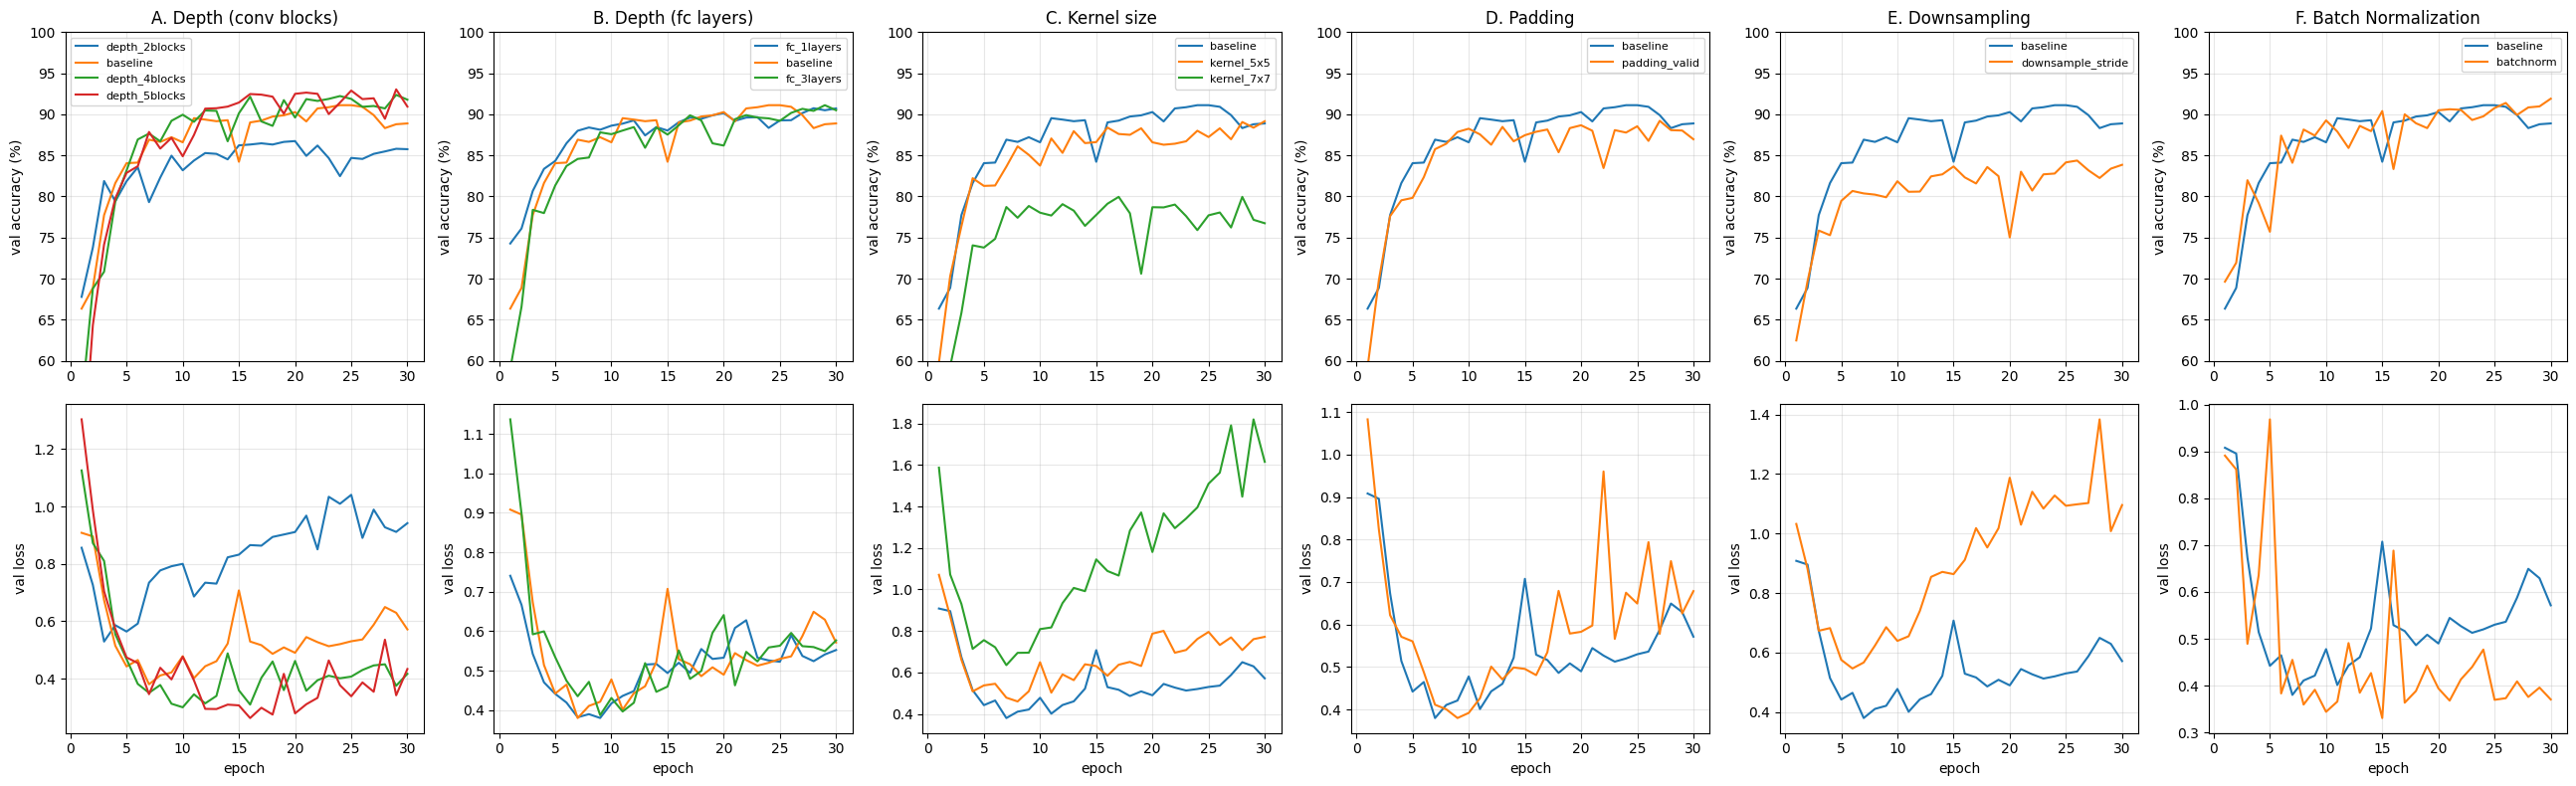

In [16]:
groups = {
    "A. Depth (conv blocks)": ["depth_2blocks", "baseline", "depth_4blocks", "depth_5blocks"],
    "B. Depth (fc layers)": ["fc_1layers", "baseline", "fc_3layers"],
    "C. Kernel size": ["baseline", "kernel_5x5", "kernel_7x7"],
    "D. Padding": ["baseline", "padding_valid"],
    "E. Downsampling": ["baseline", "downsample_stride"],
    "F. Batch Normalization": ["baseline", "batchnorm"],
}

fig, axes = plt.subplots(2, 6, figsize=(26, 8))
epochs = range(1, n_epochs + 1)
for col, (title, names) in enumerate(groups.items()):
    for name in names:
        axes[0, col].plot(epochs, all_histories[name]["val_acc"], label=name)
        axes[1, col].plot(epochs, all_histories[name]["val_loss"], label=name)
    axes[0, col].set_title(title); axes[0, col].set_ylabel("val accuracy (%)"); axes[0, col].set_ylim(60, 100)
    axes[1, col].set_ylabel("val loss"); axes[1, col].set_xlabel("epoch")
    axes[0, col].legend(fontsize=8); axes[0, col].grid(alpha=0.3); axes[1, col].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Accuracy vs number of parameters

Is a bigger network always better?

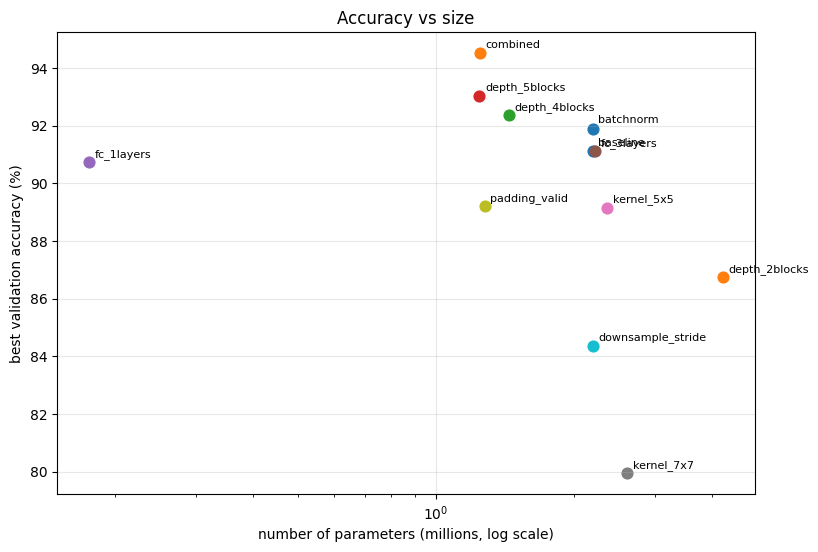

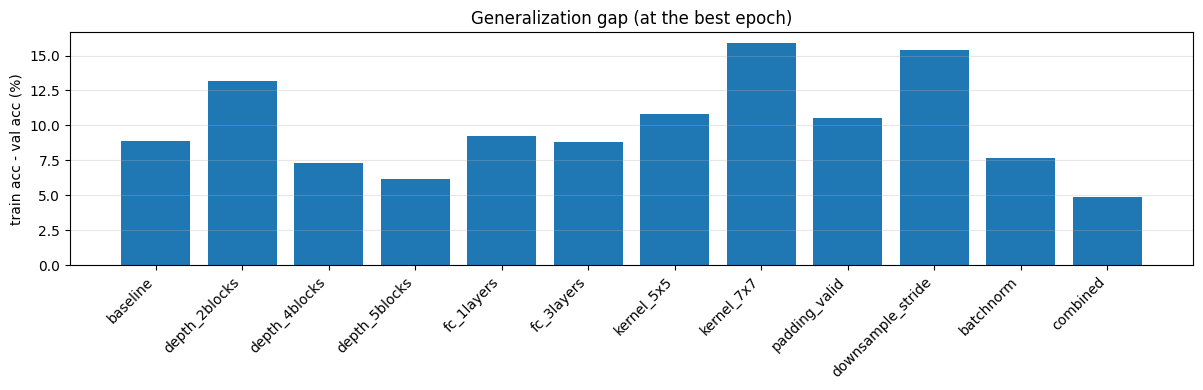

In [17]:
plt.figure(figsize=(9, 6))
for name, s in all_summaries.items():
    plt.scatter(s["params"] / 1e6, s["best_val_acc"], s=60)
    plt.annotate(name, (s["params"] / 1e6, s["best_val_acc"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
plt.xscale("log")
plt.xlabel("number of parameters (millions, log scale)"); plt.ylabel("best validation accuracy (%)")
plt.title("Accuracy vs size"); plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(12, 4))
names = list(all_summaries.keys())
plt.bar(names, [all_summaries[n]["gen_gap"] for n in names])
plt.ylabel("train acc - val acc (%)"); plt.title("Generalization gap (at the best epoch)")
plt.xticks(rotation=45, ha="right"); plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

## e. Best architecture on the test set

We select the configuration with the **best validation accuracy** and evaluate its checkpoint on the unseen test set. Its configuration is saved (`NB2_best_config.json`) and used as the starting point of NB3 (optimizers & learning rates).

In [18]:
best_name = best_of(list(all_summaries.keys()))
best_config = all_configs[best_name]
print("best configuration:", best_name, best_config)

best_net = ConfigNet(**best_config).to(device)
best_net.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB2_%s.pth" % best_name), map_location=device))
test_loss, test_acc, test_per_class_acc, test_preds, test_labels = evaluate(best_net, testloader, criterion)
all_summaries[best_name]["test_acc"] = test_acc

print('Accuracy of the network on the %d test images: %.2f %%' % (len(testset), test_acc))
for c in range(num_classes):
    print('Accuracy of %22s : %.1f %%' % (classes[c], test_per_class_acc[c]))

with open(os.path.join(RES_DIR, "NB2_best_config.json"), "w") as f:
    json.dump({"name": best_name, "config": best_config, "test_acc": test_acc}, f, indent=2)

best configuration: combined {'n_blocks': 5, 'n_fc': 2, 'kernel_size': 3, 'padding': 'same', 'downsample': 'pool', 'use_bn': True}
Accuracy of the network on the 4050 test images: 95.36 %
Accuracy of             AnnualCrop : 93.6 %
Accuracy of                 Forest : 98.7 %
Accuracy of   HerbaceousVegetation : 93.3 %
Accuracy of                Highway : 93.1 %
Accuracy of             Industrial : 97.3 %
Accuracy of                Pasture : 96.0 %
Accuracy of          PermanentCrop : 89.9 %
Accuracy of            Residential : 97.3 %
Accuracy of                  River : 96.0 %
Accuracy of                SeaLake : 97.8 %


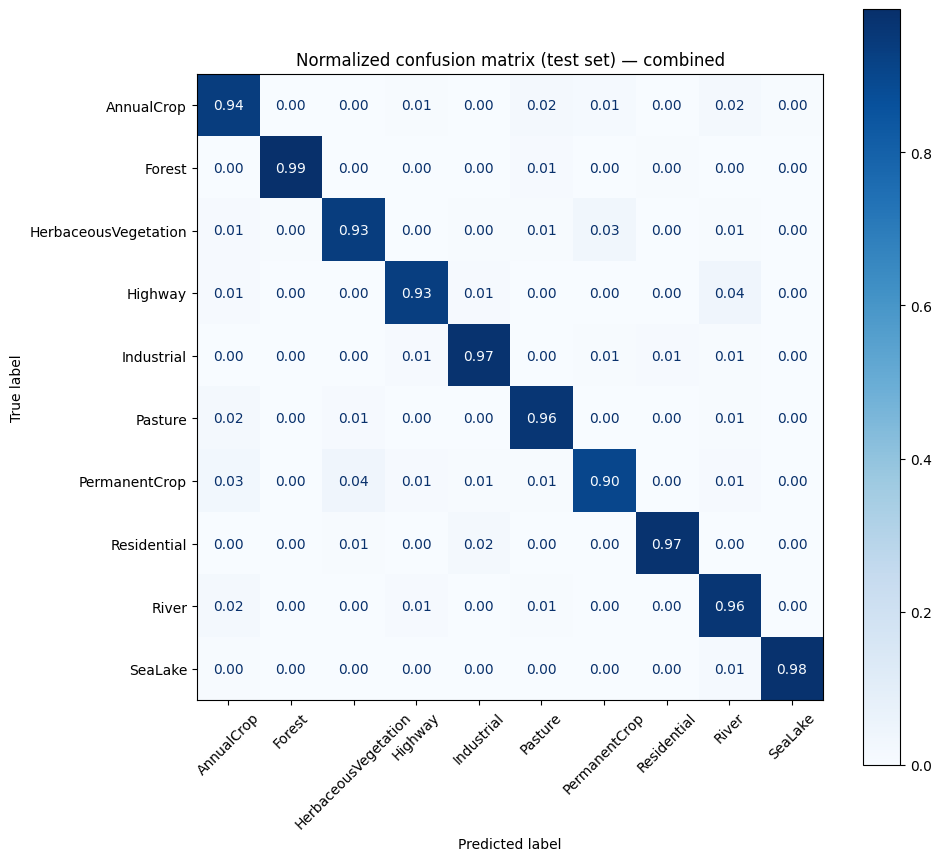

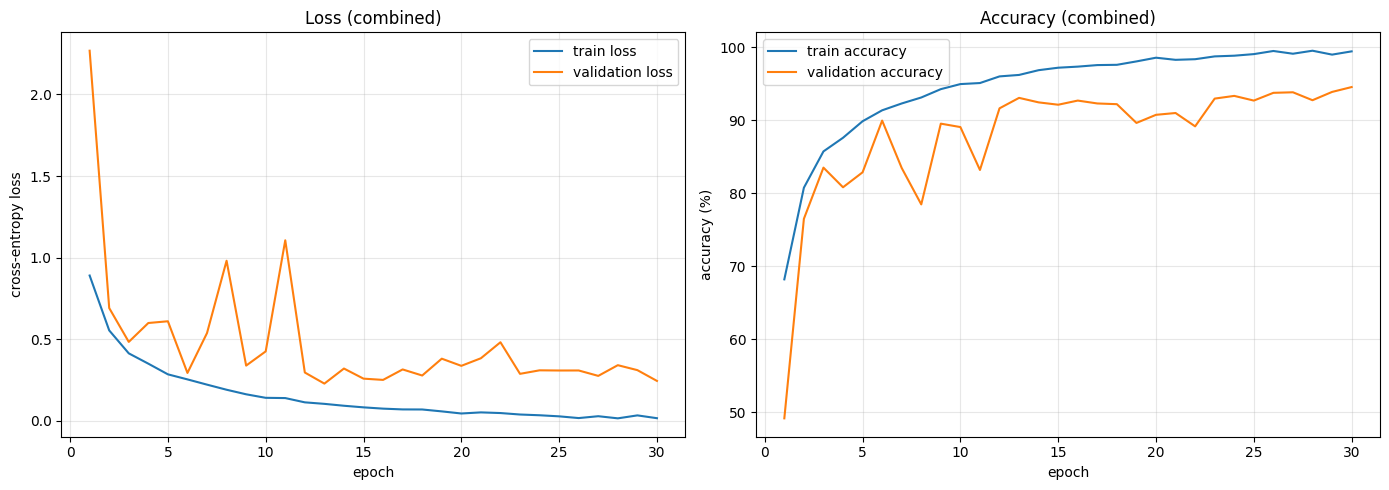

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(test_labels, test_preds, normalize="true")
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=ax, cmap="Blues", values_format=".2f", xticks_rotation=45)
ax.set_title("Normalized confusion matrix (test set) — %s" % best_name)
plt.tight_layout()
plt.show()

def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(epochs, history["train_loss"], label="train loss")
    ax1.plot(epochs, history["val_loss"], label="validation loss")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("cross-entropy loss"); ax1.set_title("Loss " + title)
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(epochs, history["train_acc"], label="train accuracy")
    ax2.plot(epochs, history["val_acc"], label="validation accuracy")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy (%)"); ax2.set_title("Accuracy " + title)
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_history(all_histories[best_name], "(%s)" % best_name)

## f. Load a saved checkpoint and test it on unseen mini-batches

Any of the configurations can be reloaded: we only need its configuration (to build the same `ConfigNet`) and its `.pth` file.

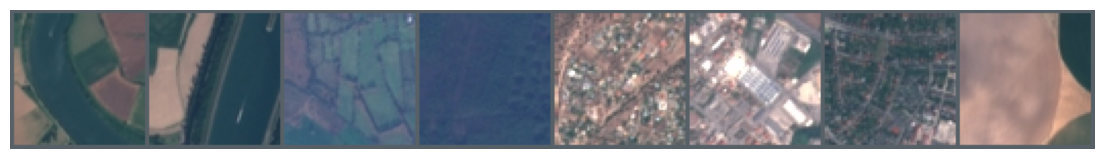

GroundTruth:  River | River | Pasture | Forest | Residential | Industrial | Residential | AnnualCrop
Predicted  :  River (1.00) | River (1.00) | Pasture (1.00) | Forest (1.00) | Residential (1.00) | Industrial (1.00) | Residential (1.00) | AnnualCrop (1.00)


In [20]:
NAME = best_name   # try for example "kernel_7x7" or "batchnorm"
config = all_configs[NAME]

trainednet = ConfigNet(**config)
trainednet.load_state_dict(torch.load(os.path.join(CKPT_DIR, "NB2_%s.pth" % NAME), map_location="cpu"))
trainednet.eval()  # important with BatchNorm: use the running statistics

def imshow(img):
    img = img * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    npimg = img.clamp(0, 1).numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")

demo_loader = DataLoader(testset, batch_size=8, shuffle=True)
images, labels = next(iter(demo_loader))
with torch.no_grad():
    outputs = trainednet(images)
    softmax = nn.Softmax(dim=1)
    probs = softmax(outputs)
    conf, predicted = torch.max(probs, 1)

plt.figure(figsize=(14, 3))
imshow(torchvision.utils.make_grid(images, nrow=8))
plt.show()
print('GroundTruth: ', ' | '.join('%s' % classes[labels[j]] for j in range(8)))
print('Predicted  : ', ' | '.join('%s (%.2f)' % (classes[predicted[j]], conf[j]) for j in range(8)))